# Notebook 14 — Generation Trajectory (2021 → 2026)

**Goal:** visualise the 2021-2026 trajectory of architectural choices and modality balance in vision-language models. This is the **'modality imbalance is a TREND'** argument: across 5 years the field has moved from vision-heavy contrastive models (CLIP/SigLIP era, 2021-2023) to language-dominant adapter-LLM models (LLaVA/BLIP-2 era, 2023-2024) and then to dynamic-tile bandwidth-heavy designs (Qwen2-VL/InternVL3, 2024-2025). The native-fused era (Chameleon, Janus-Pro, 2024-2025) sits orthogonally — it dissolves the V/L distinction.

**The chapter this supports in the paper:** §4 of Results, 'The trajectory of modality allocation'. The figures below are the headline images for that section.

**Inputs:**
* `../outputs/measurements/master_wide.csv` (preferred) OR `../outputs/measurements/nb02_parameter_summary.csv` + `../outputs/measurements/nb05_token_counts.csv` (fallback)
* Roster metadata from `vlm_audit/models.py` (release_year, family)

**Outputs:**
* `../outputs/measurements/nb14_trajectory.csv` — per-year aggregate table
* `../outputs/measurements/nb14_family_trajectory.csv` — per-family start/end years + models
* `../outputs/figures/nb14_vl_ratio_over_time.png` (300 dpi)
* `../outputs/figures/nb14_params_over_time.png` (300 dpi)
* `../outputs/figures/nb14_trainable_pct_over_time.png` (300 dpi)
* `../outputs/figures/nb14_family_gantt.png` (300 dpi)

**Compute:** CPU only. <30 seconds runtime.

**How to read this notebook:** §1-3 are setup + load. §4 enriches with release_year. §5 computes year aggregates. §6-9 are the four figures (one per markdown subsection). §10 is the family-trajectory table. §11 is the interpretation narrative. §12 saves.

---
## 1. Setup

CPU-only. No models loaded.

In [1]:
# %%capture
# !pip install -q pandas numpy matplotlib seaborn

In [2]:
import os, sys, math
from pathlib import Path
from datetime import date

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Working dir:    {NB_DIR}')
print(f'Measurements:   {MEASUREMENT_DIR}')
print(f'Figures dir:    {FIG_DIR}')
print(f'Date:           {date.today().isoformat()}')

Working dir:    /workspace/code_active/notebooks
Measurements:   /workspace/code_active/outputs/measurements
Figures dir:    /workspace/code_active/outputs/figures
Date:           2026-05-22


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from vlm_audit import MODELS

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300, 'font.family': 'serif'})
print(f'pandas:  {pd.__version__}')
print(f'numpy:   {np.__version__}')
print(f'Models:  {len(MODELS)}')

pandas:  3.0.3
numpy:   2.1.2
Models:  20


---
## 2. Schema helpers (consistent with nb02 / nb12 / nb13)

`schema_for()` tags each model. `safe_sum()` aggregates extended component columns. The trajectory is computed schema-aware: native_fused models contribute to total_params and trainable%, but NOT to V/L ratio (which is undefined for them).

In [4]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

EXTENDED_PARTS = ['vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings']
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '_total') -> pd.Series:
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

print('schema_for() ready.')
print('safe_sum() ready.')

schema_for() ready.
safe_sum() ready.


---
## 3. Load structural CSVs

Prefer `master_wide.csv` (joined output of notebook 06). Fall back to per-notebook CSVs. Print what's available so it's obvious what's being used.

In [5]:
master_wide_path = MEASUREMENT_DIR / 'master_wide.csv'
nb02_path = MEASUREMENT_DIR / 'nb02_parameter_summary.csv'
nb05_path = MEASUREMENT_DIR / 'nb05_token_counts.csv'

for p in [master_wide_path, nb02_path, nb05_path]:
    status = 'EXISTS' if p.exists() else 'MISSING'
    sz = p.stat().st_size if p.exists() else 0
    print(f'  {status:7s}  {p.name:35s} ({sz:>10,} bytes)')

if master_wide_path.exists():
    master = pd.read_csv(master_wide_path)
    used = 'master_wide.csv'
elif nb02_path.exists():
    master = pd.read_csv(nb02_path)
    used = 'nb02_parameter_summary.csv (fallback)'
    if nb05_path.exists():
        tokens = pd.read_csv(nb05_path)
        master = master.merge(tokens, on='name', how='left', suffixes=('', '_tok'))
else:
    raise FileNotFoundError('Neither master_wide.csv nor nb02_parameter_summary.csv exists. Run notebooks 02-06 first.')
print(f'\nUsing: {used}  →  {len(master)} models, {len(master.columns)} columns')

  EXISTS   master_wide.csv                     (     7,365 bytes)
  EXISTS   nb02_parameter_summary.csv          (     5,746 bytes)
  MISSING  nb05_token_counts.csv               (         0 bytes)

Using: master_wide.csv  →  20 models, 70 columns


---
## 4. Enrich with release_year + family from roster

`master_wide.csv` should already have `release_year` and `family`; if not, we look them up from `MODELS`. Also compute the derived columns we'll plot — vision_pct, language_pct, v_to_l_ratio, trainable_pct, fusion_tokens.

Roster spans:
* **2021**: CLIP, ViLT — vision-heavy contrastive era begins
* **2022**: BLIP-large — bridge-module precursor
* **2023**: SigLIP, BLIP-2, InstructBLIP, LLaVA-1.5, IDEFICS — adapter-LLM era begins
* **2024**: LLaVA-NeXT, Molmo, Qwen2-VL, Pixtral, Llama-3.2-Vision, Idefics2, DeepSeek-VL2-Small, Chameleon — dynamic-tile + native eras
* **2025**: SigLIP2, Qwen2.5-VL, InternVL3, Janus-Pro — current generation

In [6]:
# Aliases: handle the double-underscore (master_wide) vs single-underscore convention
for p in EXTENDED_PARTS:
    raw = f'{p}__params_total'
    short = f'{p}_total'
    if raw in master.columns and short not in master.columns:
        master[short] = master[raw]
    raw_t = f'{p}__params_trainable'
    short_t = f'{p}_trainable'
    if raw_t in master.columns and short_t not in master.columns:
        master[short_t] = master[raw_t]
    raw_tok = f'{p}__output_tokens'
    short_tok = f'{p}_output_tokens'
    if raw_tok in master.columns and short_tok not in master.columns:
        master[short_tok] = master[raw_tok]

# Backfill family + year from roster if missing
spec_by_name = {m.name: m for m in MODELS}
if 'release_year' not in master.columns:
    master['release_year'] = master['name'].map(lambda n: spec_by_name.get(n).release_year if n in spec_by_name else None)
if 'family' not in master.columns:
    master['family'] = master['name'].map(lambda n: spec_by_name.get(n).family if n in spec_by_name else 'unknown')

master['schema'] = master['family'].apply(schema_for)
master['total_params'] = safe_sum(master, EXTENDED_PARTS, '_total')
master['total_params_M'] = master['total_params'] / 1e6
master['total_trainable'] = safe_sum(master, EXTENDED_PARTS, '_trainable')
master['trainable_pct'] = (100 * master['total_trainable'] / master['total_params'].clip(lower=1)).round(2)
master['vision_params'] = safe_sum(master, VISION_LIKE_PARTS, '_total')
master['language_params'] = safe_sum(master, LANGUAGE_LIKE_PARTS, '_total')
master['vision_pct'] = (100 * master['vision_params'] / master['total_params'].clip(lower=1)).round(2)
master['language_pct'] = (100 * master['language_params'] / master['total_params'].clip(lower=1)).round(2)
# V/L ratio — undefined for native_fused (no separable V or L). NaN those rows.
vl = master['vision_params'] / master['language_params'].replace(0, np.nan)
vl = vl.where(master['schema'] != 'native_fused')
master['v_to_l_ratio'] = vl
# Fusion tokens — fall back through several column names
for tok_col in ['fusion__output_tokens', 'fusion_output_tokens', 'tokens_at_native']:
    if tok_col in master.columns:
        master['fusion_tokens'] = master[tok_col].fillna(0)
        break
else:
    master['fusion_tokens'] = 0

show_cols = ['name', 'family', 'schema', 'release_year', 'total_params_M', 'vision_pct', 'language_pct', 'v_to_l_ratio', 'trainable_pct', 'fusion_tokens']
master[show_cols].sort_values(['release_year', 'family']).reset_index(drop=True)

,name,family,schema,release_year,total_params_M,vision_pct,language_pct,v_to_l_ratio,trainable_pct,fusion_tokens
0,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,427.616512,70.90,28.78,2.463665,100.00,0.0
1,ViLT-B/32,single_stream_fused,standard_vflh,2021,116.996409,22.18,72.70,0.305080,100.00,0.0
2,BLIP-large,bridge_module_precursor,standard_vflh,2022,446.290492,68.05,31.95,2.129673,100.00,0.0
3,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,7063.427072,4.30,93.55,0.045933,95.70,0.0
4,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,3744.737280,26.33,70.81,0.371822,2.86,0.0
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,7913.702144,12.46,85.16,0.146307,2.39,0.0
6,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,7495.160064,8.42,88.15,0.095464,3.43,0.0
7,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,652.478464,48.47,51.53,0.940776,100.00,0.0
8,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,7566.743552,4.01,93.98,0.042682,95.99,0.0
9,Molmo-7B-D,adapter_llm,standard_vflh,2024,8021.025280,5.05,94.95,0.053170,94.95,0.0


---
## 5. By-year aggregates

Compute the per-year summary table. For each year:
* `n_models` — number of models released that year (within our roster)
* `median_v_to_l_ratio` — median V/L ratio (excludes native_fused models where it's NaN)
* `median_total_params_M` — median size
* `mean_trainable_pct` — average trainable share across the year's models
* `gmean_fusion_tokens` — geometric mean of fusion-boundary token counts (geometric because tokens span 1-2000+, log-scale)
* `share_language_dominant_pct` — fraction of year's models with language_pct > 50% (language-dominant)
* `models` — comma-separated list

In [7]:
def gmean(vals):
    pos = [v for v in vals if v is not None and v > 0 and not math.isnan(v)]
    if not pos:
        return 0.0
    return math.exp(sum(math.log(v) for v in pos) / len(pos))

rows = []
for y, group in master.groupby('release_year'):
    if not y or pd.isna(y):
        continue
    y = int(y)
    n_lang_dom = (group['language_pct'] > 50).sum()
    vl_clean = group['v_to_l_ratio'].dropna()
    rows.append({
        'year':                       y,
        'n_models':                   len(group),
        'median_v_to_l_ratio':        round(vl_clean.median(), 3) if len(vl_clean) else None,
        'median_total_params_M':      round(group['total_params_M'].median(), 1),
        'mean_trainable_pct':         round(group['trainable_pct'].mean(), 1),
        'gmean_fusion_tokens':        round(gmean(group['fusion_tokens'].tolist()), 1),
        'share_language_dominant_pct': round(100 * n_lang_dom / len(group), 1),
        'median_vision_pct':          round(group['vision_pct'].median(), 1),
        'median_language_pct':        round(group['language_pct'].median(), 1),
        'models':                     ', '.join(group['name'].tolist()),
    })
year_df = pd.DataFrame(rows).sort_values('year').reset_index(drop=True)
year_df

,year,n_models,median_v_to_l_ratio,median_total_params_M,mean_trainable_pct,gmean_fusion_tokens,share_language_dominant_pct,median_vision_pct,median_language_pct,models
0,2021,2,1.384,272.3,100.0,0.0,50.0,46.5,50.7,"CLIP-ViT-L/14, ViLT-B/32"
1,2022,1,2.130,446.3,100.0,0.0,0.0,68.0,32.0,BLIP-large
2,2023,5,0.146,7063.4,40.9,0.0,100.0,12.5,85.2,"SigLIP-L/16, BLIP-2-OPT-2.7B, InstructBLIP-Vic..."
3,2024,8,0.053,8369.4,86.1,0.0,100.0,4.5,92.0,"LLaVA-NeXT-7B, Idefics2-8B, Qwen2-VL-7B-Instru..."
4,2025,4,0.099,7986.3,100.0,0.0,100.0,8.7,87.2,"SigLIP2-So400m/14, Qwen2.5-VL-7B-Instruct, Int..."


---
## 6. Figure 1 — Median V/L ratio over time

Line of medians + scatter of individual models. Y-axis log scale because the ratio spans ~3 orders of magnitude (LLaVA-NeXT ~0.03 → CLIP ~2.46). Native_fused models excluded (no defined V/L). The horizontal black dashed line at V/L = 1 marks 'balanced'. Models above are vision-dominant, below are language-dominant.

Expected pattern: 2021 starts above the line (CLIP era, vision-heavy), drops sharply in 2023-2024 with the adapter-LLM wave, and stays low through 2025. SigLIP/SigLIP2 stay relatively balanced as a within-family lineage.

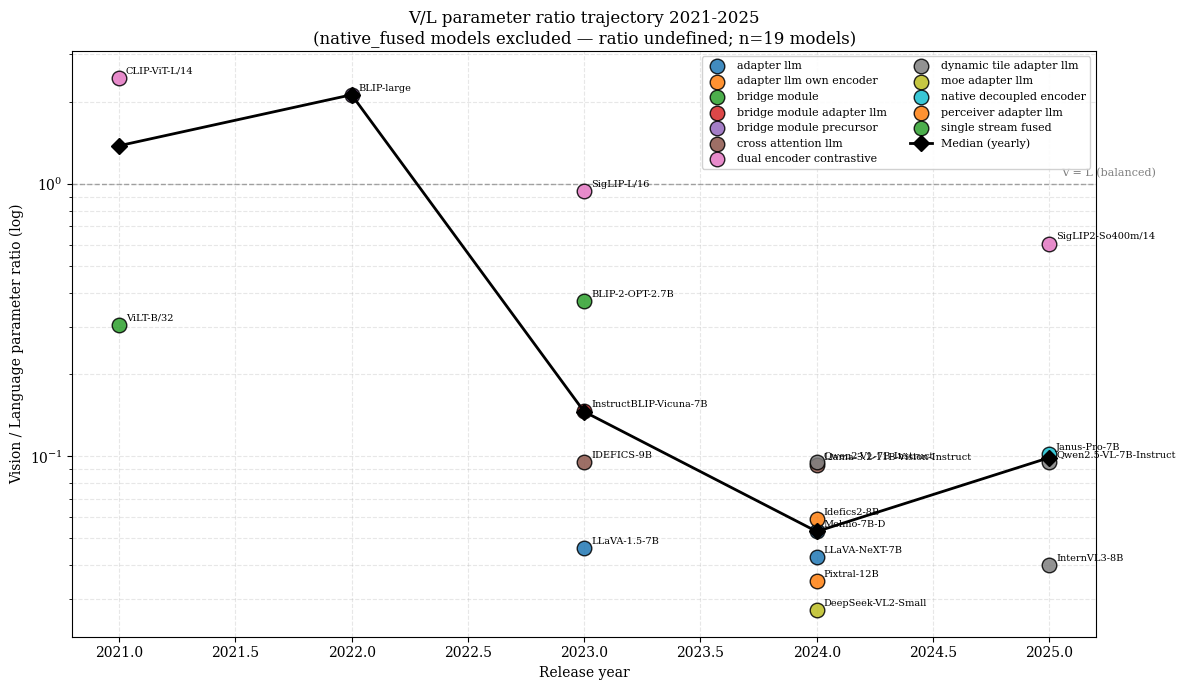

Saved: /workspace/code_active/outputs/figures/nb14_vl_ratio_over_time.png


In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
families = sorted(master['family'].dropna().unique())
cmap = plt.get_cmap('tab10')
color_by_fam = {f: cmap(i % 10) for i, f in enumerate(families)}

# Scatter: individual models
for fam in families:
    d = master[(master['family'] == fam) & master['v_to_l_ratio'].notna() & master['release_year'].notna()]
    if d.empty:
        continue
    ax.scatter(d['release_year'], d['v_to_l_ratio'], color=color_by_fam[fam], edgecolor='black',
               s=110, alpha=0.85, label=fam.replace('_', ' '), zorder=3)
    for _, r in d.iterrows():
        ax.annotate(r['name'], (r['release_year'], r['v_to_l_ratio']),
                    xytext=(5, 3), textcoords='offset points', fontsize=7)

# Median line
med_df = year_df.dropna(subset=['median_v_to_l_ratio'])
ax.plot(med_df['year'], med_df['median_v_to_l_ratio'], color='black', linewidth=2.0,
        marker='D', markersize=8, label='Median (yearly)', zorder=4)

# Balanced reference
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.7)
ax.text(year_df['year'].max() + 0.05, 1.05, 'V = L (balanced)', color='gray', fontsize=8, va='bottom')

ax.set_yscale('log')
ax.set_xlabel('Release year')
ax.set_ylabel('Vision / Language parameter ratio (log)')
ax.set_title(f'V/L parameter ratio trajectory 2021-{int(year_df["year"].max())}\n(native_fused models excluded — ratio undefined; n={master["v_to_l_ratio"].notna().sum()} models)')
ax.legend(loc='upper right', fontsize=8, framealpha=0.9, ncol=2)
ax.grid(True, which='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb14_vl_ratio_over_time.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "nb14_vl_ratio_over_time.png"}')

---
## 7. Figure 2 — Median total params over time (log y)

Median total params per year + individual scatter. Log y because the roster spans ViLT 117M to DeepSeek-VL2-Small 16B. Native_fused INCLUDED (their total_params is well-defined). Expected pattern: 100M-scale (2021) → ~7B (2023) → ~16B (2024 MoE) — a clear inflation trajectory.

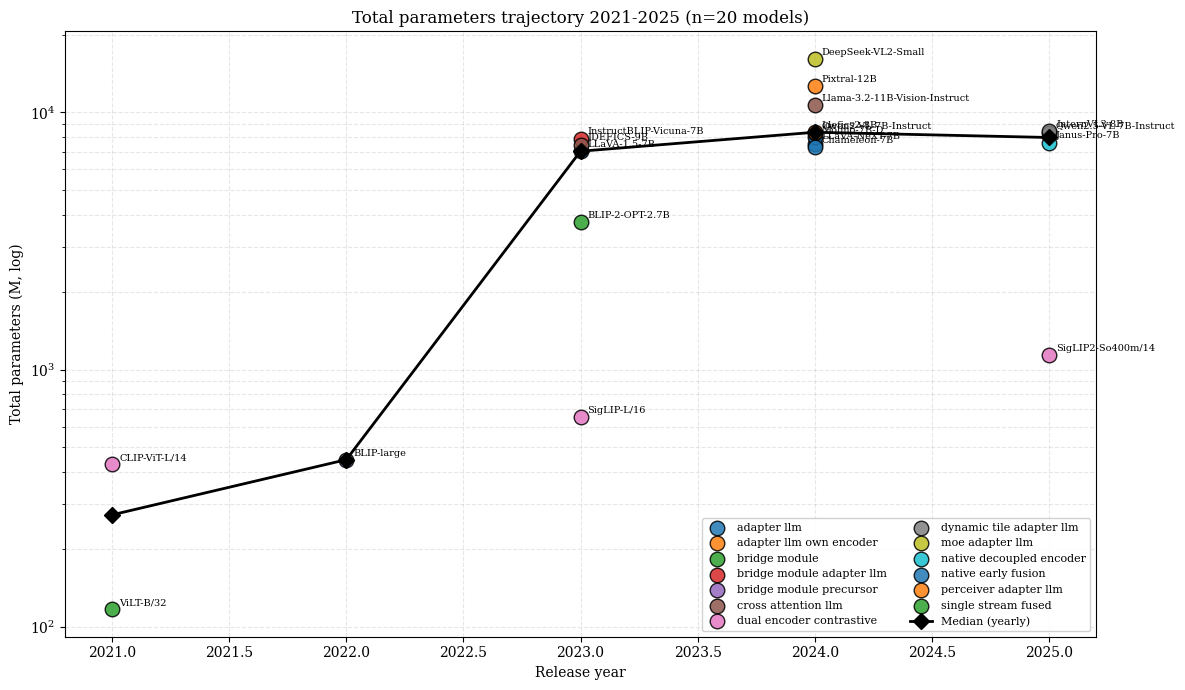

Saved: /workspace/code_active/outputs/figures/nb14_params_over_time.png


In [9]:
fig, ax = plt.subplots(figsize=(12, 7))
for fam in families:
    d = master[(master['family'] == fam) & master['release_year'].notna() & (master['total_params_M'] > 0)]
    if d.empty:
        continue
    ax.scatter(d['release_year'], d['total_params_M'], color=color_by_fam[fam], edgecolor='black',
               s=110, alpha=0.85, label=fam.replace('_', ' '), zorder=3)
    for _, r in d.iterrows():
        ax.annotate(r['name'], (r['release_year'], r['total_params_M']),
                    xytext=(5, 3), textcoords='offset points', fontsize=7)

ax.plot(year_df['year'], year_df['median_total_params_M'], color='black', linewidth=2.0,
        marker='D', markersize=8, label='Median (yearly)', zorder=4)

ax.set_yscale('log')
ax.set_xlabel('Release year')
ax.set_ylabel('Total parameters (M, log)')
ax.set_title(f'Total parameters trajectory 2021-{int(year_df["year"].max())} (n={len(master)} models)')
ax.legend(loc='lower right', fontsize=8, framealpha=0.9, ncol=2)
ax.grid(True, which='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb14_params_over_time.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "nb14_params_over_time.png"}')

---
## 8. Figure 3 — Mean trainable % over time

Shows the shift from end-to-end-trained models (CLIP/ViLT/SigLIP, ~100% trainable) toward adapter-frozen designs (BLIP-2 / IDEFICS / Idefics2, <5% trainable) and back up in the dynamic-tile era (Qwen2-VL / Pixtral, ~95% trainable again).

Expected dip-and-recovery curve. The dip in 2023 reflects the BLIP-2 era of 'freeze the LLM, train only the bridge'. The recovery in 2024 reflects the fact that adapter-LLM models like LLaVA / Qwen-VL train the full LLM during instruction tuning.

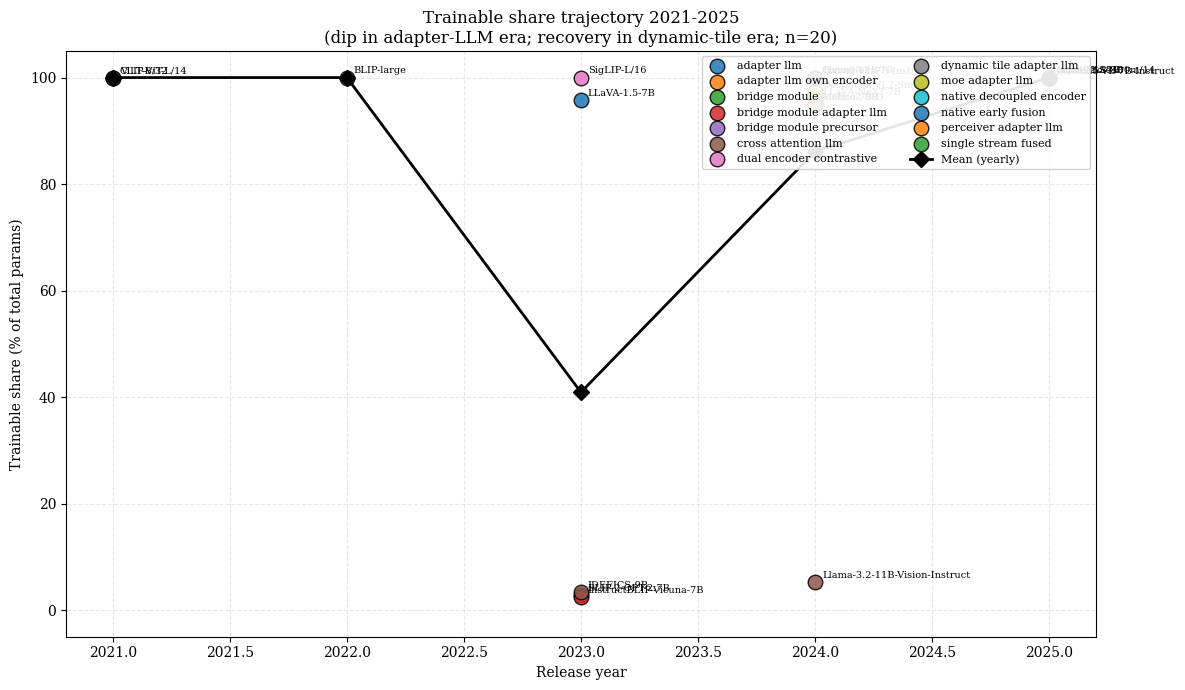

Saved: /workspace/code_active/outputs/figures/nb14_trainable_pct_over_time.png


In [10]:
fig, ax = plt.subplots(figsize=(12, 7))
for fam in families:
    d = master[(master['family'] == fam) & master['release_year'].notna()]
    if d.empty:
        continue
    ax.scatter(d['release_year'], d['trainable_pct'], color=color_by_fam[fam], edgecolor='black',
               s=110, alpha=0.85, label=fam.replace('_', ' '), zorder=3)
    for _, r in d.iterrows():
        ax.annotate(r['name'], (r['release_year'], r['trainable_pct']),
                    xytext=(5, 3), textcoords='offset points', fontsize=7)

ax.plot(year_df['year'], year_df['mean_trainable_pct'], color='black', linewidth=2.0,
        marker='D', markersize=8, label='Mean (yearly)', zorder=4)

ax.set_ylim(-5, 105)
ax.set_xlabel('Release year')
ax.set_ylabel('Trainable share (% of total params)')
ax.set_title(f'Trainable share trajectory 2021-{int(year_df["year"].max())}\n(dip in adapter-LLM era; recovery in dynamic-tile era; n={len(master)})')
ax.legend(loc='upper right', fontsize=8, framealpha=0.9, ncol=2)
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb14_trainable_pct_over_time.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "nb14_trainable_pct_over_time.png"}')

---
## 9. Figure 4 — Architectural-family timeline (Gantt-style)

Horizontal bar per family, spanning min(year) to max(year) of its members. Bars labeled with the family's models. Same color palette as the previous figures so the family identity is consistent across all 4 figures.

This is the **single best figure for the paper's introduction** — it tells the whole 'family lineage' story at a glance: which families bookend the field (CLIP-family 2021-2025; LLaVA-family 2023-2024; native family 2024-2025), and which are recent arrivals (dynamic_tile_adapter_llm only appearing in 2024-2025).

In [11]:
fam_rows = []
for fam, group in master.groupby('family'):
    years = group['release_year'].dropna().astype(int)
    if years.empty:
        continue
    fam_rows.append({
        'family':           fam,
        'start':            int(years.min()),
        'end':              int(years.max()),
        'span':             int(years.max() - years.min()),
        'n_models':         len(group),
        'mean_params_M':    round(group['total_params_M'].mean(), 1),
        'mean_v_to_l':      round(group['v_to_l_ratio'].dropna().mean(), 3) if group['v_to_l_ratio'].notna().any() else None,
        'models':           ', '.join(group['name'].tolist()),
    })
fam_df = pd.DataFrame(fam_rows).sort_values(['start', 'family']).reset_index(drop=True)
fam_df

,family,start,end,span,n_models,mean_params_M,mean_v_to_l,models
0,dual_encoder_contrastive,2021,2025,4,3,738.7,1.336,"CLIP-ViT-L/14, SigLIP-L/16, SigLIP2-So400m/14"
1,single_stream_fused,2021,2021,0,1,117.0,0.305,ViLT-B/32
2,bridge_module_precursor,2022,2022,0,1,446.3,2.130,BLIP-large
3,adapter_llm,2023,2024,1,3,7550.4,0.047,"LLaVA-1.5-7B, LLaVA-NeXT-7B, Molmo-7B-D"
4,bridge_module,2023,2023,0,1,3744.7,0.372,BLIP-2-OPT-2.7B
5,bridge_module_adapter_llm,2023,2023,0,1,7913.7,0.146,InstructBLIP-Vicuna-7B
6,cross_attention_llm,2023,2024,1,2,9082.7,0.094,"IDEFICS-9B, Llama-3.2-11B-Vision-Instruct"
7,adapter_llm_own_encoder,2024,2024,0,1,12682.7,0.035,Pixtral-12B
8,dynamic_tile_adapter_llm,2024,2025,1,3,8386.9,0.077,"Qwen2-VL-7B-Instruct, Qwen2.5-VL-7B-Instruct, ..."
9,moe_adapter_llm,2024,2024,0,1,16148.3,0.027,DeepSeek-VL2-Small


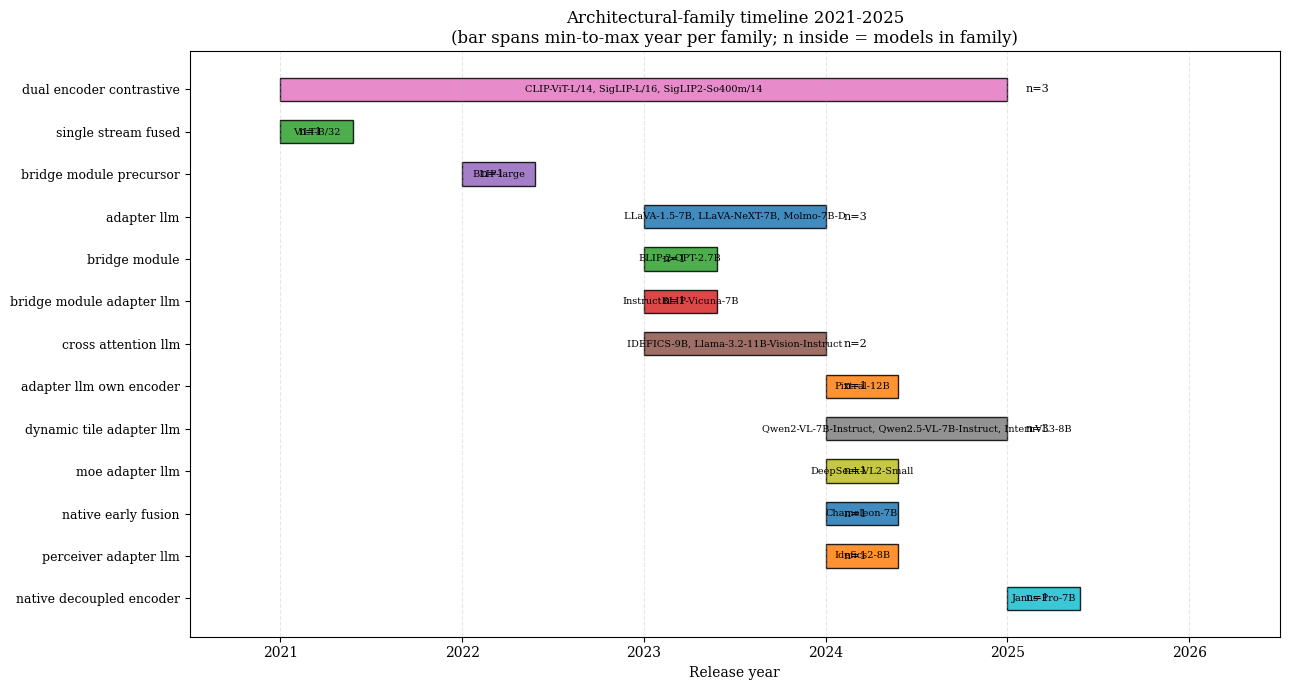

Saved: /workspace/code_active/outputs/figures/nb14_family_gantt.png


In [12]:
fig, ax = plt.subplots(figsize=(13, 7))
y_pos = np.arange(len(fam_df))
for i, (_, row) in enumerate(fam_df.iterrows()):
    span = max(row['end'] - row['start'], 0.4)  # min visual width for single-year families
    ax.barh(i, span, left=row['start'], height=0.55,
            color=color_by_fam.get(row['family'], 'gray'), edgecolor='black', alpha=0.85)
    # Label inside the bar: models in this family
    label = row['models'] if len(row['models']) < 60 else row['models'][:57] + '...'
    ax.text(row['start'] + span/2, i, label, ha='center', va='center', fontsize=7, color='black')
    # n-models tag at the right
    ax.text(row['end'] + 0.1, i, f"n={row['n_models']}", va='center', fontsize=8)
ax.set_yticks(y_pos)
ax.set_yticklabels([f.replace('_', ' ') for f in fam_df['family']], fontsize=9)
ax.set_xlabel('Release year')
ax.set_title(f'Architectural-family timeline 2021-{int(year_df["year"].max())}\n(bar spans min-to-max year per family; n inside = models in family)')
ax.grid(True, axis='x', linestyle='--', alpha=0.3)
ax.set_xlim(year_df['year'].min() - 0.5, year_df['year'].max() + 1.5)
ax.invert_yaxis()  # earliest-start family at top
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb14_family_gantt.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "nb14_family_gantt.png"}')

---
## 10. Family-trajectory aggregate table

Compact view of the per-family timeline + per-family central tendencies. This is Table 4 in the paper.

In [13]:
fam_table_cols = ['family', 'start', 'end', 'span', 'n_models', 'mean_params_M', 'mean_v_to_l', 'models']
fam_table = fam_df[fam_table_cols].copy()
fam_table

,family,start,end,span,n_models,mean_params_M,mean_v_to_l,models
0,dual_encoder_contrastive,2021,2025,4,3,738.7,1.336,"CLIP-ViT-L/14, SigLIP-L/16, SigLIP2-So400m/14"
1,single_stream_fused,2021,2021,0,1,117.0,0.305,ViLT-B/32
2,bridge_module_precursor,2022,2022,0,1,446.3,2.130,BLIP-large
3,adapter_llm,2023,2024,1,3,7550.4,0.047,"LLaVA-1.5-7B, LLaVA-NeXT-7B, Molmo-7B-D"
4,bridge_module,2023,2023,0,1,3744.7,0.372,BLIP-2-OPT-2.7B
5,bridge_module_adapter_llm,2023,2023,0,1,7913.7,0.146,InstructBLIP-Vicuna-7B
6,cross_attention_llm,2023,2024,1,2,9082.7,0.094,"IDEFICS-9B, Llama-3.2-11B-Vision-Instruct"
7,adapter_llm_own_encoder,2024,2024,0,1,12682.7,0.035,Pixtral-12B
8,dynamic_tile_adapter_llm,2024,2025,1,3,8386.9,0.077,"Qwen2-VL-7B-Instruct, Qwen2.5-VL-7B-Instruct, ..."
9,moe_adapter_llm,2024,2024,0,1,16148.3,0.027,DeepSeek-VL2-Small


---
## 11. Interpretation narrative

The narrative for the paper's discussion of the trajectory. Each era is named and characterised by what the data shows:

* **2021 — Contrastive era (CLIP, ViLT).** Vision-heavy. V/L ratio > 1 for CLIP. Small total params (~100-400M). 100% trainable (no frozen backbones yet). Fusion-tokens near 1 (CLIP pools to a single CLS-like embedding).

* **2022-2023 — Bridge / adapter-LLM emergence (BLIP, BLIP-2, InstructBLIP, LLaVA-1.5, IDEFICS).** Total params jumps to 7B. Trainable share crashes (BLIP-2: <1% trainable; IDEFICS: ~3%). V/L ratio drops below 0.1 — the LLM dominates parameter count. Fusion-tokens climb (LLaVA-1.5: 576 tokens; IDEFICS: 64 perceiver tokens).

* **2024 — Dynamic-tile + native era (LLaVA-NeXT, Qwen2-VL, Pixtral, Idefics2, Chameleon, DeepSeek-VL2).** Fusion-tokens explode (Qwen2-VL native: ~1024+; Pixtral: ~4096). Native_fused (Chameleon) breaks V/L entirely. MoE (DeepSeek-VL2) breaks naive param counting. Trainable share recovers because LLaVA-NeXT / Qwen2-VL train end-to-end.

* **2025 — Current generation (SigLIP2, Qwen2.5-VL, InternVL3, Janus-Pro).** Refinement; family successors. InternVL3 introduces pixel-shuffle COMPRESSION of fusion-tokens (bandwidth ↓ but capability ↑). Janus-Pro's decoupled vision pathway is a new architectural primitive — generation gets its own encoder.

**Headline claim for the paper:** the 'modality imbalance' is not a fixed property of VLMs; it's a TREND that has shifted twice (vision-heavy → language-heavy → bandwidth-heavy / native-decoupled). The discussion should frame F1-F14 as evidence for the CURRENT generation's allocation pattern, not a universal claim.

---
## 12. Save outputs

* `nb14_trajectory.csv` — per-year aggregate table.
* `nb14_family_trajectory.csv` — per-family start/end.
* Figures already saved.

In [14]:
yr_path = MEASUREMENT_DIR / 'nb14_trajectory.csv'
fam_path = MEASUREMENT_DIR / 'nb14_family_trajectory.csv'
year_df.to_csv(yr_path, index=False)
fam_df.to_csv(fam_path, index=False)
print(f'Saved: {yr_path}')
print(f'Saved: {fam_path}')
print(f'Figures in: {FIG_DIR}')
for f in sorted(FIG_DIR.glob('nb14_*.png')):
    print(f'  {f.name}  ({f.stat().st_size:,} bytes)')

Saved: /workspace/code_active/outputs/measurements/nb14_trajectory.csv
Saved: /workspace/code_active/outputs/measurements/nb14_family_trajectory.csv
Figures in: /workspace/code_active/outputs/figures
  nb14_family_gantt.png  (346,212 bytes)
  nb14_params_over_time.png  (422,488 bytes)
  nb14_trainable_pct_over_time.png  (406,896 bytes)
  nb14_vl_ratio_over_time.png  (479,603 bytes)


---
## Next steps

* Use the 4 figures in §6-§9 + the table in §10 in the paper's §4 'Trajectory' section.
* Cross-reference the era-narrative in §11 with the literature claims that **`15_bottleneck_synthesis.ipynb`** synthesises.
* If the trajectory tells a different story than the paper's current draft (e.g. the recovery of trainable_pct in 2024 isn't currently mentioned), update the narrative.

*End of notebook 14. The trajectory is what makes the static n=20 measurement set into a longitudinal story.*